# Ejemplo calibrado 

- El modelo calibrado describe bien los datos: las emisiones sí se repiten de un día a otro.
- La censura casi no cuesta (< 0.15 %): perder información los días en que la contaminación llega a cero apenas cambia las decisiones.
- Una regla simple de umbral (tipo contingencia), bien calibrada, queda a menos de 1 % de la política óptima.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
D = "datos/"

## Los datos

- **Fuente:** RAMA datos horarios 2022–2025 (vienen datos por hora, estacion y contaminante, lo pase a un numero por dia)
- **Qué mide:** cuánta contaminación hay en el aire (concentración) de pm2.5 que es materia particulada fina
- **Serie usada:** promedio diario de PM2.5 de la ciudad (11 estaciones con buena cobertura los cuatro años)
- **Días excluidos:** 24–26 de diciembre y 31 de diciembre–2 de enero

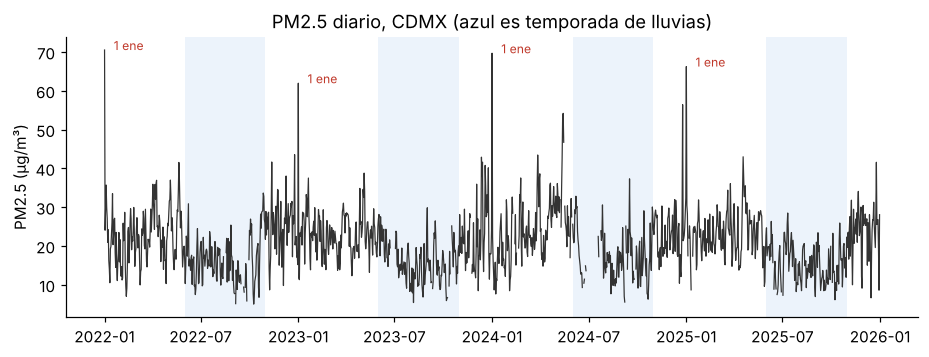

In [2]:
df = pd.read_csv(D + "pm25_diario.csv", parse_dates=["date"], index_col="date")

fig, ax = plt.subplots(figsize=(10, 3.3))
for y in range(2022, 2026):
    ax.axvspan(pd.Timestamp(f"{y}-06-01"), pd.Timestamp(f"{y}-10-31"), color="#4a90d9", alpha=0.1, lw=0)
ax.plot(df.index, df.pm25, lw=0.8, color="#333333")
for y in range(2022, 2026):
    ax.annotate("1 ene", (pd.Timestamp(f"{y}-01-01"), df.pm25.get(pd.Timestamp(f"{y}-01-01"))),
                xytext=(6, 0), textcoords="offset points", fontsize=8, color="#c0392b")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("PM2.5 diario, CDMX (azul es temporada de lluvias)")
plt.show()

la contaminación es más alta en la temporada seca (noviembre–mayo) y los picos más grandes son cada 1 de enero. Trabajamos solo con la temporada seca porque si no delta cambiaria (fraccion de contaminación que se disipa solita). La contaminación nunca llega a cero por el limite de det4eccion  (el mínimo es 5 µg/m³).

## Calibrar el modelo

** primero deducimos las emisiones, como en el paper:

    emisiones de hoy = contaminación de mañana − (1 − δ) · contaminación de hoy

sobre delta...
- Los datos no pueden separar delta de la persistencia de las emisiones
- La literatura (de Foy et al., 2006) dice que el valle se ventila en menos de 12 horas, así que **δ es alto**.
- Por eso probamos **δ = 0.5, 0.7 y 0.9**.

** luego ajustamos los dos regimenes (días de emisión baja y alta) y la función de persistencia qué tan probable es un día alto mañana según lo emitido hoy.

La gráfica compara cuánto se emite en promedio "mañana" según lo emitido "hoy": puntos = datos, líneas = modelos.

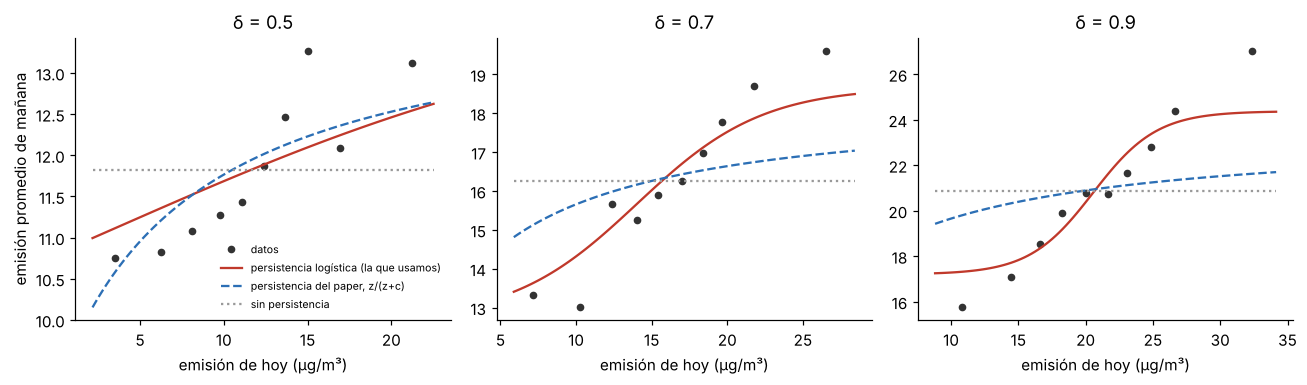

In [3]:
pts = pd.read_csv(D + "calibracion_datos.csv")
cur = pd.read_csv(D + "calibracion_modelos.csv")
estilo = {"logistica": ("#c0392b", "-", "persistencia logística (la que usamos)"),
          "paper": ("#2c6fb5", "--", "persistencia del paper, z/(z+c)"),
          "sin_persistencia": ("#999999", ":", "sin persistencia")}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, d in zip(axes, [0.5, 0.7, 0.9]):
    p = pts[pts.delta == d]
    ax.plot(p.hoy, p.manana, "o", color="#333333", ms=4, label="datos")
    for m, (c, ls, lab) in estilo.items():
        g = cur[(cur.delta == d) & (cur.modelo == m)]
        ax.plot(g.hoy, g.manana, color=c, ls=ls, label=lab)
    ax.set_title(f"δ = {d}")
    ax.set_xlabel("emisión de hoy (µg/m³)")
axes[0].set_ylabel("emisión promedio de mañana")
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

- Si "hoy" fue alto, "mañana" también suele serlo
- La logística (roja) sigue a los datos mejor
- Toda la teoría del paper sigue valiendo con la logística: la creencia se sigue resumiendo en un solo número w

## ¿El modelo calibrado se parece a los datos reales?

Simulamos el modelo calibrado (δ = 0.9) sin limpieza, igual que en los datos reales, y lo comparamos con la temporada seca real.

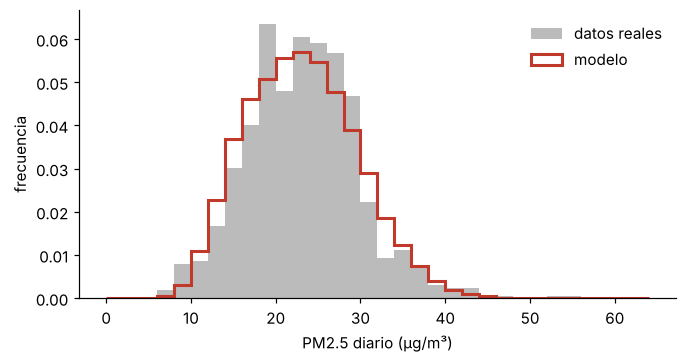

Promedio  -> real: 23.2   modelo: 23.1
Variación -> real: 6.6    modelo: 6.5


In [4]:
real = pd.read_csv(D + "real_seca.csv").real
sim = pd.read_csv(D + "simulado.csv").simulado

fig, ax = plt.subplots(figsize=(7, 3.4))
bins = range(0, 66, 2)
ax.hist(real, bins=bins, density=True, color="#bbbbbb", label="datos reales")
ax.hist(sim, bins=bins, density=True, histtype="step", lw=2, color="#c0392b", label="modelo")
ax.set_xlabel("PM2.5 diario (µg/m³)"); ax.set_ylabel("frecuencia")
ax.legend(frameon=False)
plt.show()
print(f"Promedio  -> real: {real.mean():.1f}   modelo: {sim.mean():.1f}")
print(f"Variación -> real: {real.std():.1f}    modelo: {sim.std():.1f}")

El modelo reproduce los niveles reales: mismo promedio (~23 µg/m³) y misma variabilidad.

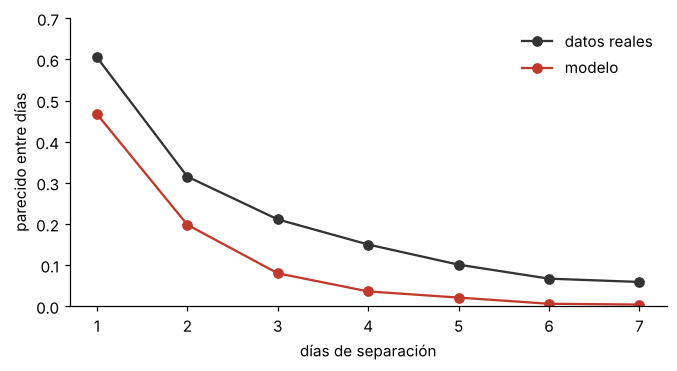

In [5]:
p = pd.read_csv(D + "persistencia.csv")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(p.rezago, p.real, "o-", color="#333333", label="datos reales")
ax.plot(p.rezago, p.modelo, "o-", color="#c0392b", label="modelo")
ax.set_xlabel("días de separación"); ax.set_ylabel("parecido entre días")
ax.set_ylim(0, 0.7); ax.legend(frameon=False)
plt.show()

El modelo captura que un día se parece al siguiente, pero se queda corto: en la realidad hay episodios de contaminación de varios días que el modelo no reproduce, porque sus emisiones solo dependen del día anterior.

## Política óptima con los parámetros calibrados

Equivalente a la Figura 1 de la Sección 7, pero con números de la CDMX (δ = 0.9). w es la probabilidad que la ciudad le da a que hoy sea un día de emisiones altas. Los costos de contaminación y limpieza los elegimos nosotros (no salen de los datos).

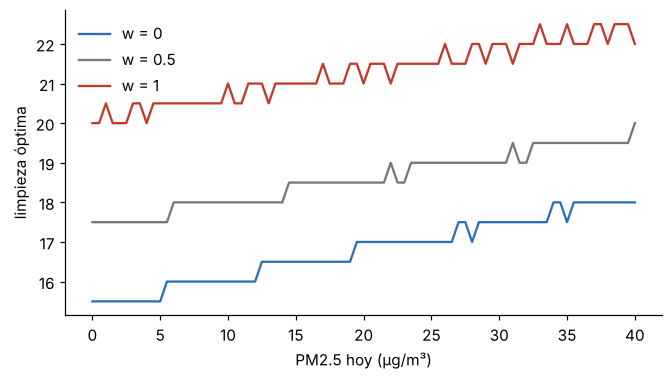

In [6]:
pol = pd.read_csv(D + "politica.csv")
g = pol[pol.delta == 0.9]
fig, ax = plt.subplots(figsize=(7, 3.6))
for w, col in [(0.0, "#2c6fb5"), (0.5, "#777777"), (1.0, "#c0392b")]:
    s = g[g.w == w]
    ax.plot(s.contaminacion, s.limpieza, color=col, label=f"w = {w:g}")
ax.set_xlabel("PM2.5 hoy (µg/m³)"); ax.set_ylabel("limpieza óptima")
ax.legend(frameon=False)
plt.show()

La ciudad limpia más cuando hay más contaminación y cuando cree que hoy será un día de emisiones altas, igual que en el ejemplo original del paper.

## Resultados

Resolvimos el modelo calibrado con iteración de valores, y simulamos 60,000 días comparando:

- la ciudad de paper, que pierde información los días que la contaminación llega a cero
- una ciudad con informacion completa donde siempre sabe cuánto se emitió
- una ciudad ingenua que ignora las emisiones que se repiten

- **reglas simples:** limpiar siempre lo mismo, o limpiar más cuando se pasa un umbral (tipo contingencia), en su mejor versión posible

Los costos se muestran dos casos: limpieza barata (κ = 0.02) y cara (κ = 0.05).

In [7]:
r = pd.read_csv(D + "resultados.csv")
r["limpieza"] = r.kappa.map({0.02: "barata", 0.05: "cara"})
tabla = r.rename(columns={
    "costo_censura_pct": "No ver emisiones (censura)",
    "costo_ignorar_persistencia_pct": "Ignorar persistencia",
    "costo_regla_umbral_pct": "Regla de umbral",
    "costo_regla_constante_pct": "Regla constante",
}).set_index(["limpieza", "delta"])[["No ver emisiones (censura)", "Ignorar persistencia",
                                     "Regla de umbral", "Regla constante"]].sort_index()
print("Costo extra (%). Censura e ignorar persistencia: vs. información completa. Reglas: vs. política óptima del paper.")
tabla.round(2)

Costo extra (%). Censura e ignorar persistencia: vs. información completa. Reglas: vs. política óptima del paper.


No ver emisiones (censura)  Ignorar persistencia  \
limpieza delta                                                     
barata   0.5                          0.05                  0.15   
         0.7                          0.14                  1.13   
         0.9                          0.01                  1.56   
cara     0.5                          0.03                  0.08   
         0.7                         -0.00                  0.15   
         0.9                         -0.00                 -0.01   

                Regla de umbral  Regla constante  
limpieza delta                                    
barata   0.5               0.52             2.09  
         0.7               0.62             2.37  
         0.9               0.43             1.96  
cara     0.5               0.31             1.47  
         0.7               0.04             0.60  
         0.9              -0.06            -0.04

- No ver las emisiones cuesta casi nada en todos los casos. Diferencias menores a ~0.1 % son ruido numérico
- Ignorar la persistencia cuesta 1–1.6 % cuando δ es alto y limpiar es barato
- Una regla de umbral bien calibrada queda a ~0.5 % de la política óptima, limpiar siempre lo mismo, a ~2 %.

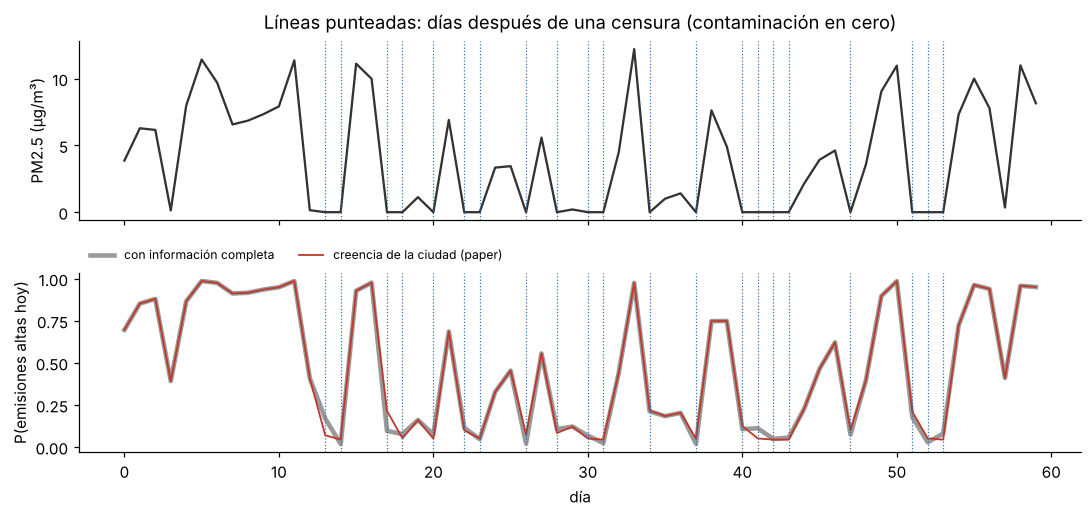

In [8]:
t = pd.read_csv(D + "trayectoria.csv")
fig, axes = plt.subplots(2, 1, figsize=(10, 4.8), sharex=True)
axes[0].plot(t.dia, t.contaminacion, color="#333333")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[1].plot(t.dia, t.info_completa, color="#999999", lw=3, label="con información completa")
axes[1].plot(t.dia, t.creencia, color="#c0392b", lw=1.2, label="creencia de la ciudad (paper)")
axes[1].set_ylabel("P(emisiones altas hoy)")
axes[1].set_xlabel("día")
for d_ in t.dia[t.censurado_ayer]:
    for ax in axes:
        ax.axvline(d_, color="#2c6fb5", ls=":", lw=0.8)
axes[1].legend(frameon=False, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
axes[0].set_title("Líneas punteadas: días después de una censura (contaminación en cero)", pad=8)
plt.tight_layout(); plt.show()